<a href="https://colab.research.google.com/github/Sayrinix/Laboratorio-S3-CDD/blob/main/S3_Sayrina_Luciano_CDD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 3 — Análisis exploratorio de tu conjunto de datos
**Ciencia de Datos · Semana 3 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 1) · RA3 (transversal) |
| **Duración estimada** | 1,5 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_limpio.csv`, producido en la semana 2 |
| **Producto** | Este cuaderno completo — **es la Entrega 2** |
| **Estudiante** | _Sayrina Luciano Jofré_ |

---



**Este cuaderno es la entrega.** No hay informe aparte. Lo que se evalúa es que cada resultado venga acompañado de su lectura: *un resultado sin interpretación no es un hallazgo, es un número suelto*.

# Reproducibilidad

En este cuaderno se utiliza el conjunto limpio en CSV, que puedes encontrar en el siguiente enlace: [mi_conjunto_limpio.csv](https://github.com/Sayrinix/Laboratorio-S3-CDD/blob/main/documentos/mi_conjunto_limpio.csv$0)

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

df = pd.read_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';')
print('Forma:', df.shape)
df.head()

Forma: (336, 13)


,codigoOC,FechaEnvioOC,Institucion,RegionOrigen,MecanismoCompra,MonedaOC,MontoTotalOC,MontoNetoOC_CLP,EstadoOC,mes_compra,MecanismoCompra_ConvenioMarco,MecanismoCompra_Licitacion,MecanismoCompra_TratoDirecto
0,624-5-AG26,2026-02-11,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,1599700.34,1344286.0,RECEPCION CONFORME,2,0,0,0
1,624-9-AG26,2026-02-13,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,4230450.00,3555000.0,RECEPCION CONFORME,2,0,0,0
2,624-11-AG26,2026-02-23,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,475997.62,399998.0,RECEPCION CONFORME,2,0,0,0
3,624-26-AG26,2026-03-13,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,535500.00,450000.0,RECEPCION CONFORME,3,0,0,0
4,624-37-AG26,2026-03-27,GOBIERNO REGIONAL IV REGION COQUIMBO,Coquimbo,CompraAgil,CLP,1773100.00,1490000.0,ACEPTADA,3,0,0,0


### Punto de partida

Antes de explorar, recuerda a dónde vas. Copia aquí lo que escribiste en la Entrega 1:

- **Mi pregunta analítica es:**_¿Cómo se distribuyen los montos netos en pesos chilenos de las órdenes de compra de los Gobiernos Regionales de Coquimbo, Metropolitana y Valparaíso durante el primer semestre de 2026, según el mes y el mecanismo de contratación?_
- **Una fila de mi conjunto representa:** _Una fila de mi conjunto representa una orden de compra individual emitida por uno de los tres Gobiernos Regionales analizados durante el primer semestre de 2026. Cada orden se identifica mediante un código único (`codigoOC`) y contiene información sobre su institución, mecanismo de contratación, fecha y monto neto en pesos chilenos._

Todo lo que sigue debe servir para responder esa pregunta. Si un gráfico no aporta a ella, sobra.

---
## Parte 1 · Análisis univariado

Una variable a la vez. El objetivo es conocer la forma de cada una antes de relacionarlas.\
El análisis univariado consiste en estudiar una variable a la vez, sin relacionarla todavía con otras variables del conjunto de datos.

Su objetivo es conocer cómo se distribuyen los valores, identificar valores extremos, detectar posibles anomalías y comprender el comportamiento general de cada variable.

In [26]:
# Resumen numérico de todas las variables cuantitativas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MontoTotalOC,336.0,17275042.09,1.367542e+08,13.45,230236.75,636674.0,2998651.25,2.399888e+09
MontoNetoOC_CLP,336.0,16660591.88,1.157980e+08,28000.00,311472.50,822821.0,4972182.46,2.016712e+09
mes_compra,336.0,4.09,1.520000e+00,1.00,3.00,4.0,5.00,6.000000e+00
MecanismoCompra_ConvenioMarco,336.0,0.26,4.400000e-01,0.00,0.00,0.0,1.00,1.000000e+00
MecanismoCompra_Licitacion,336.0,0.20,4.000000e-01,0.00,0.00,0.0,0.00,1.000000e+00
MecanismoCompra_TratoDirecto,336.0,0.08,2.800000e-01,0.00,0.00,0.0,0.00,1.000000e+00


### 1. Análisis de cada variable

**MontoTotalOC:** Presenta una media de 17.275.042,09 y una mediana de 636.674,00, evidenciando una distribución fuertemente asimétrica hacia valores elevados. Sin embargo, esta variable contiene montos expresados en diferentes monedas, por lo que sus estadísticas no permiten realizar comparaciones monetarias directas.

**MontoNetoOC_CLP:** Registra una media de $16.660.591,88 y una mediana de $822.821 La diferencia entre ambas medidas, junto con una desviación estándar de $115.798.010,16, evidencia una elevada dispersión y una marcada asimetría positiva, asociada a la presencia de órdenes de gran magnitud. La mediana representa mejor el monto típico.

**mes_compra:** Presenta valores entre 1 y 6, correspondientes al primer semestre de 2026. Su media de 4,09 y mediana de 4 sitúan el centro de la distribución temporal alrededor de abril, aunque estas medidas no permiten determinar el mes con mayor monto acumulado.

**MecanismoCompra_ConvenioMarco:** Al ser una variable binaria, su media de 0,26 indica que aproximadamente el 26 % de las órdenes corresponde a Convenio Marco.

**MecanismoCompra_Licitacion:** Su media de 0,20 indica que aproximadamente el 20 % de las órdenes corresponde a Licitación.

**MecanismoCompra_TratoDirecto:** Su media de 0,08 indica que aproximadamente el 8 % de las órdenes corresponde a Trato Directo.

La categoría Compra Ágil se encuentra representada como categoría de referencia de la codificación y no aparece como variable independiente. Las proporciones indicadas corresponden a cantidades de órdenes, no a participación en los montos monetarios.

### 2. Hallazgos importantes y conclusión

**Hallazgos importantes:**

- **Elevada dispersión de los montos:** La variable **MontoNetoOC_CLP** presenta una media de 16.660.591,88 CLP y una mediana de $822.821, lo que evidencia una marcada asimetría positiva. Esto sugiere que unas pocas órdenes de gran magnitud influyen considerablemente en el promedio.

- **Diferencias entre mecanismos de contratación:** Convenio Marco representa aproximadamente el 26 % de las órdenes, Licitación el 20 % y Trato Directo el 8 %. Estas proporciones reflejan la frecuencia de utilización de cada mecanismo, pero no necesariamente su participación en los montos totales.

- **Distribución temporal:** Las órdenes abarcan los seis primeros meses de 2026, con una media temporal de 4,09, correspondiente a un centro de distribución cercano a abril. Sin embargo, es necesario analizar las frecuencias y los montos mensuales para identificar posibles concentraciones.

**Conclusión:**

El análisis descriptivo inicial evidencia una elevada variabilidad en los montos de las órdenes de compra y diferencias en la frecuencia de utilización de los mecanismos de contratación. Estos resultados sugieren la necesidad de profundizar mediante visualizaciones y comparaciones por mes, mecanismo y Gobierno Regional, para determinar cómo se distribuyen los montos registrados y qué factores podrían estar asociados a sus diferencias.



### ✏️ Actividad 1.1 — Distribuciones

Grafica el histograma de **al menos tres variables numéricas** relevantes para tu pregunta. Para cada una, responde en la celda de texto siguiente:

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?
- ¿Tiene una joroba o más de una? Si tiene más de una, **busca la categoría que la explica** (Ejercicio 1 del cuaderno resuelto).
- ¿Ves picos regulares o valores que se repiten sospechosamente? (Ejercicio 3).

Para esta actividad utilizaremos las siguientes tres variables numéricas:
- **MontoNetoOC_CLP**: Nos permitirá observar cómo se distribuyen los montos netos de las 336 órdenes e identificar visualmente la concentración de valores pequeños y la presencia de montos extremos.

- **log_monto_neto** (variable derivada): Se crea una variable mediante np.log10(MontoNetoOC_CLP). Esto comprime la escala y permite distinguir mejor la distribución de los montos sin que las órdenes extremadamente grandes dominen el gráfico.

- **mes_compra**: Permite visualizar cuántas órdenes se registraron en enero, febrero, marzo, abril, mayo y junio de 2026. Como los meses son valores discretos, se utilizarán intervalos centrados en los números enteros del 1 al 6.


In [48]:
# Tu código aquí
import numpy as np

# Verificar que todos los montos sean positivos
print((df["MontoNetoOC_CLP"] > 0).all())

True


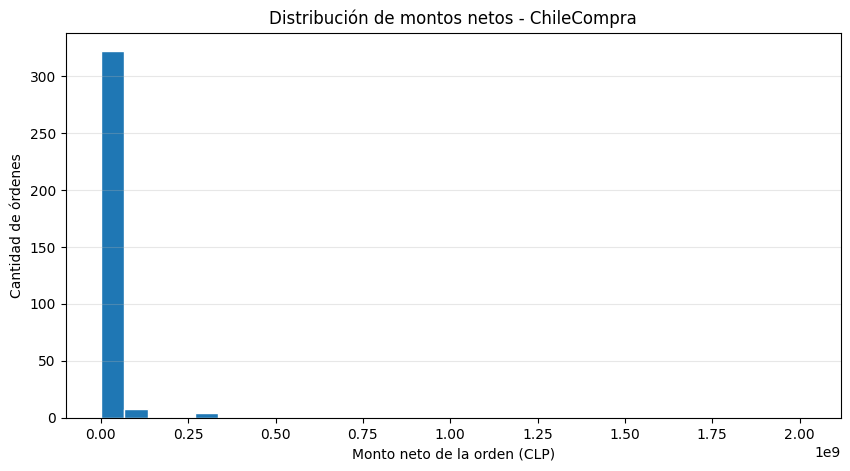

In [28]:

#Histograma 1
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["MontoNetoOC_CLP"],
    bins=30,
    edgecolor="white"
)

plt.title("Distribución de montos netos - ChileCompra")
plt.xlabel("Monto neto de la orden (CLP)")
plt.ylabel("Cantidad de órdenes")
plt.grid(axis="y", alpha=0.3)

plt.show()


**Histograma de MontoNetoOC_CLP:**

El histograma presenta una distribución marcadamente asimétrica hacia la derecha, con una elevada concentración de órdenes en los intervalos de menor monto y una cantidad reducida de contrataciones de gran magnitud.

Esta característica es consistente con la diferencia entre la media (16.660.591,88 CLP) y la mediana (822.821 CLP), así como con la presencia de 46 órdenes estadísticamente atípicas identificadas durante la preparación del conjunto.

Los valores extremos amplían considerablemente la escala horizontal, dificultando la visualización de las diferencias entre las órdenes de menor monto. Por ello, resulta conveniente complementar este gráfico con una representación en escala logarítmica, sin eliminar ni modificar los registros originales.

In [29]:
#Creación de variable
import numpy as np

df["log_monto_neto"] = np.log10(df["MontoNetoOC_CLP"])

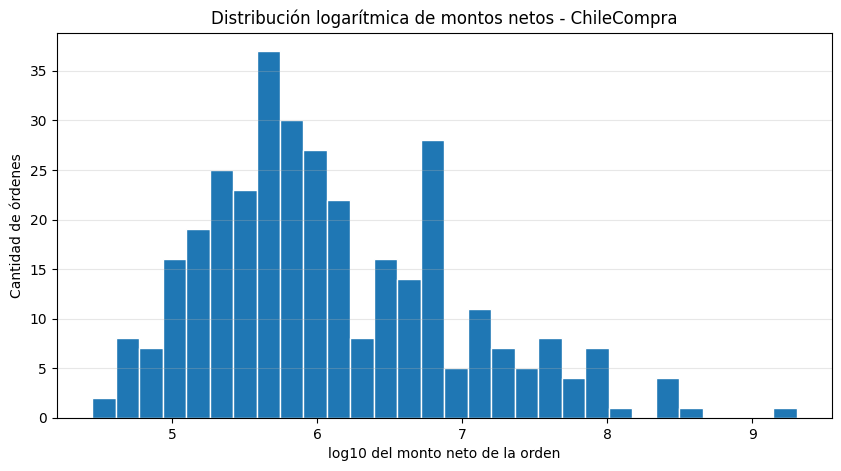

In [30]:
#Histograma 2
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["log_monto_neto"],
    bins=30,
    edgecolor="white"
)

plt.title("Distribución logarítmica de montos netos - ChileCompra")
plt.xlabel("log10 del monto neto de la orden")
plt.ylabel("Cantidad de órdenes")
plt.grid(axis="y", alpha=0.3)

plt.show()

**Histograma de log_monto_neto:**

La transformación logarítmica permite visualizar con mayor claridad la distribución de los montos netos de las órdenes de compra. A diferencia del histograma original, donde la mayoría de los registros se concentraba en el primer intervalo, esta representación permite distinguir diferentes rangos monetarios.

Se observa una mayor concentración de órdenes entre los valores logarítmicos 5 y 6, equivalentes aproximadamente a montos entre 100.000 y 1.000.000 CLP. También se identifican órdenes de montos superiores, aunque con frecuencias generalmente menores.

La distribución mantiene una cola hacia la derecha, con algunos valores extremos que superan los 100 millones CLP y una orden cercana a los $2.000 millones.

En conclusión, ambos histogramas evidencian una elevada heterogeneidad en los montos de contratación. La transformación logarítmica facilita la interpretación de esta variabilidad sin eliminar ni modificar las órdenes originales.

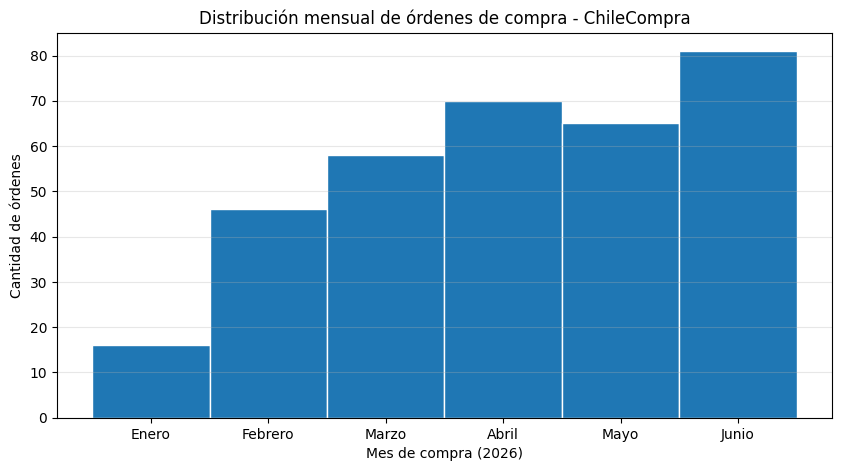

In [31]:

#Histograma 3 - mescompra
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

plt.hist(
    df["mes_compra"],
    bins=np.arange(0.5, 7.5, 1),
    edgecolor="white"
)

plt.title("Distribución mensual de órdenes de compra - ChileCompra")
plt.xlabel("Mes de compra (2026)")
plt.ylabel("Cantidad de órdenes")

plt.xticks(
    [1, 2, 3, 4, 5, 6],
    ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio"]
)

plt.grid(axis="y", alpha=0.3)
plt.show()


In [32]:
df["mes_compra"].value_counts().sort_index()

,count
mes_compra,
1,16
2,46
3,58
4,70
5,65
6,81


**Histograma de mes_compra:**

El histograma evidencia una tendencia general creciente en la cantidad de órdenes de compra registradas durante el primer semestre de 2026. Enero presenta la menor frecuencia, con aproximadamente 16 órdenes, mientras que junio registra la mayor, con aproximadamente 81.

Entre febrero y abril se observa un incremento progresivo, seguido de una leve disminución en mayo y un nuevo aumento en junio. Estos resultados sugieren una mayor concentración de órdenes hacia el final del período analizado.

Sin embargo, la cantidad de órdenes no representa necesariamente el monto monetario acumulado de cada mes. Por ello, será necesario complementar este análisis con la distribución mensual de MontoNetoOC_CLP, para determinar si los períodos con más órdenes también presentan mayores importes registrados.

### ✏️ Actividad 1.2 — Media contra mediana

Para tu variable numérica principal, compara media, mediana y sesgo. Decide cuál de las dos reportarías en un informe y justifícalo.

In [33]:
# Tu código aquí

# Variable numérica principal
variable = df["MontoNetoOC_CLP"]

# Medidas estadísticas
media = variable.mean()
mediana = variable.median()
sesgo = variable.skew()

print(f"Media: ${media:,.2f} CLP")
print(f"Mediana: ${mediana:,.2f} CLP")
print(f"Coeficiente de asimetría: {sesgo:.2f}")


Media: $16,660,591.88 CLP
Mediana: $822,821.00 CLP
Coeficiente de asimetría: 15.67


**Justificación:**

Los resultados muestran que **MontoNetoOC_CLP** presenta una distribución fuertemente asimétrica hacia la derecha, con un coeficiente de asimetría de 15,67. Esta característica se relaciona con la presencia de órdenes de compra de gran magnitud, que elevan considerablemente el promedio.

La media alcanza 16.660.591,88 CLP, mientras que la mediana corresponde a $822.821, evidenciando una diferencia importante entre ambas medidas.

Para un informe descriptivo, se recomienda utilizar la mediana como indicador principal del monto típico de una orden de compra, debido a que es menos sensible a los valores extremos. No obstante, la media puede presentarse como medida complementaria para caracterizar la distribución general de los montos.

Este resultado coincide con los histogramas de la Actividad 1.1 y demuestra la importancia de considerar la asimetría al comparar montos entre Gobiernos Regionales y mecanismos de contratación.

### ✏️ Actividad 1.3 — Variables categóricas

Muestra la frecuencia de tus variables categóricas. Fíjate en dos cosas: categorías con muy pocos casos (¿conviene agruparlas?) y categorías que dominan el conjunto (¿sesgan la conclusión?).

+++++\
El objetivo es analizar cuántos registros pertenecen a cada categoría y determinar si algunas categorías tienen una representación mucho mayor que otras.

**Variables Categóricas**:
- **Mecanismo de Contratación**: Compra Ágil, Convenio Marco, Licitación, Trato Directo.
- **Gobierno Regional**: Metropolitana, Coquimbo, Valparaíso.

In [34]:

# Frecuencia de órdenes por mecanismo de contratación
print("Frecuencias por mecanismo:")
print(df["MecanismoCompra"].value_counts())

print("\nPorcentaje por mecanismo:")
print(
    df["MecanismoCompra"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Frecuencias por mecanismo:
MecanismoCompra
CompraAgil       151
ConvenioMarco     89
Licitacion        68
TratoDirecto      28
Name: count, dtype: int64

Porcentaje por mecanismo:
MecanismoCompra
CompraAgil       44.94
ConvenioMarco    26.49
Licitacion       20.24
TratoDirecto      8.33
Name: proportion, dtype: float64


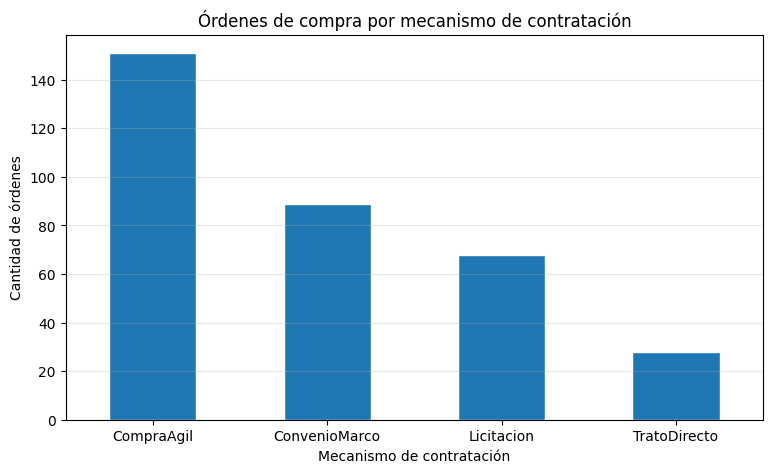

In [35]:
#Gráfico de barras Mecanismo de compra
import matplotlib.pyplot as plt

frecuencias = df["MecanismoCompra"].value_counts()

plt.figure(figsize=(9, 5))
frecuencias.plot(kind="bar", edgecolor="white")

plt.title("Órdenes de compra por mecanismo de contratación")
plt.xlabel("Mecanismo de contratación")
plt.ylabel("Cantidad de órdenes")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [36]:
# Frecuencia de órdenes por Gobierno Regional
print("\nFrecuencias por región:")
print(df["RegionOrigen"].value_counts())

print("\nPorcentaje por región:")
print(
    df["RegionOrigen"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Frecuencias por región:
RegionOrigen
Metropolitana    131
Coquimbo         109
Valparaiso        96
Name: count, dtype: int64

Porcentaje por región:
RegionOrigen
Metropolitana    38.99
Coquimbo         32.44
Valparaiso       28.57
Name: proportion, dtype: float64


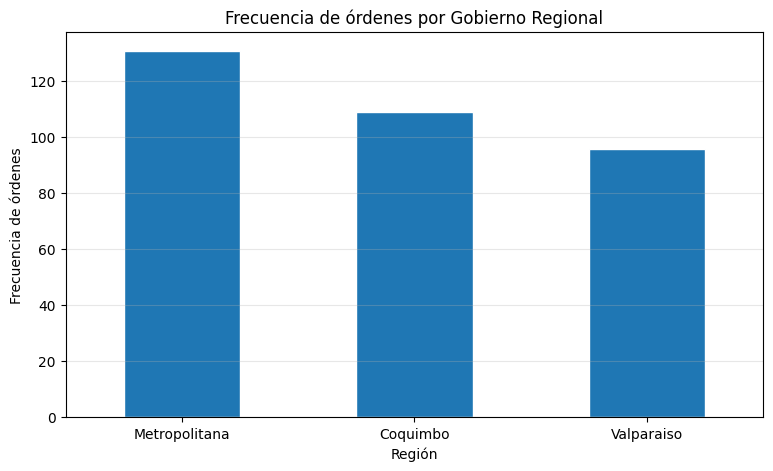

In [37]:
#Gráfico de barras Frecuencia de órdenes por Gobierno Regional
import matplotlib.pyplot as plt

frecuencias = df["RegionOrigen"].value_counts()

plt.figure(figsize=(9, 5))
frecuencias.plot(kind="bar", edgecolor="white")

plt.title("Frecuencia de órdenes por Gobierno Regional")
plt.xlabel("Región")
plt.ylabel("Frecuencia de órdenes")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

**Interpretación de frecuencias categóricas**

El análisis de las 336 órdenes de compra evidencia diferencias en la frecuencia de utilización de los mecanismos de contratación. Compra Ágil presenta la mayor participación, con 151 órdenes (44,94 %), seguido de Convenio Marco con 89 (26,49 %), Licitación con 68 (20,24 %) y Trato Directo con 28 (8,33 %).

Respecto de la distribución geográfica, el Gobierno Regional Metropolitano concentra la mayor cantidad de órdenes, con 131 registros (38,99 %), seguido de Coquimbo con 109 (32,44 %) y Valparaíso con 96 (28,57 %).

**Conclusión:** Compra Ágil predomina en términos de frecuencia, mientras que la Región Metropolitana registra la mayor cantidad de órdenes dentro del conjunto seleccionado. Sin embargo, estos resultados no permiten determinar cuáles mecanismos o regiones concentran los mayores montos monetarios. Para ello será necesario complementar el análisis mediante comparaciones de **MontoNetoOC_CLP** entre categorías.

---
## Parte 2 · Análisis bivariado y agrupación

Ahora las relaciones. Aquí es donde empiezan a aparecer los hallazgos, y también los espejismos.

### ✏️ Actividad 2.1 — Comportamiento por grupo

Agrupa por tu variable categórica más importante y compara una métrica numérica entre grupos. Usa `groupby` con al menos tres estadísticos (`count`, `median`, `std`).

**Incluye siempre el `count`.** Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos.

In [38]:
# Tu código aquí

# Comparación de montos según mecanismo de contratación

resumen_mecanismos = (
    df.groupby("MecanismoCompra")["MontoNetoOC_CLP"]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)

display(resumen_mecanismos)


,count,median,mean,std
MecanismoCompra,,,,
CompraAgil,151,644670.0,1400555.37,1.662344e+06
ConvenioMarco,89,406600.0,6685851.29,3.169888e+07
Licitacion,68,10426694.5,35948978.23,6.915639e+07
TratoDirecto,28,2247500.0,83817990.24,3.794343e+08


**Actividad 2.1 — Comportamiento por mecanismo de contratación**

El análisis agrupado evidencia diferencias importantes en los montos netos de las órdenes de compra según el mecanismo de contratación.

**Compra Ágil** presenta la mayor frecuencia, con 151 órdenes, pero registra una mediana relativamente baja de 644.670 CLP. En contraste, **Licitación** presenta la mediana más elevada, de 10.426.694,50 CLP, a pesar de contar con 68 órdenes. Esto sugiere que las licitaciones tienden a involucrar montos mayores por orden dentro del conjunto analizado.

Por otra parte, **Trato Directo** registra la media más alta, de 83.817.990,24 CLP, pero su mediana alcanza solamente 2.247.500 CLP. Esta diferencia, junto con su elevada desviación estándar de $379.434.346,76 CLP, evidencia una fuerte influencia de valores extremos. Además, al contar con 28 órdenes, sus resultados deben interpretarse con cautela.

**Conclusión:** La cantidad de órdenes no determina el monto típico de las contrataciones. Los resultados muestran diferencias relevantes entre mecanismos, particularmente en las medianas y en la dispersión monetaria. Para representar el monto típico de cada grupo, la mediana resulta más adecuada que la media debido a la asimetría de los datos. Estas diferencias son descriptivas y no permiten establecer relaciones causales entre el mecanismo utilizado y el monto contratado.

### ✏️ Actividad 2.2 — Matriz de correlación

Calcula y grafica la matriz de correlación de tus variables numéricas. Identifica los dos pares con mayor correlación.

,MontoNetoOC_CLP,log_monto_neto,mes_compra,MecanismoCompra_ConvenioMarco,MecanismoCompra_Licitacion,MecanismoCompra_TratoDirecto
MontoNetoOC_CLP,1.00,0.38,-0.08,-0.05,0.08,0.18
log_monto_neto,0.38,1.00,-0.07,-0.21,0.45,0.14
mes_compra,-0.08,-0.07,1.00,0.09,-0.01,-0.07
MecanismoCompra_ConvenioMarco,-0.05,-0.21,0.09,1.00,-0.30,-0.18
MecanismoCompra_Licitacion,0.08,0.45,-0.01,-0.30,1.00,-0.15
MecanismoCompra_TratoDirecto,0.18,0.14,-0.07,-0.18,-0.15,1.00


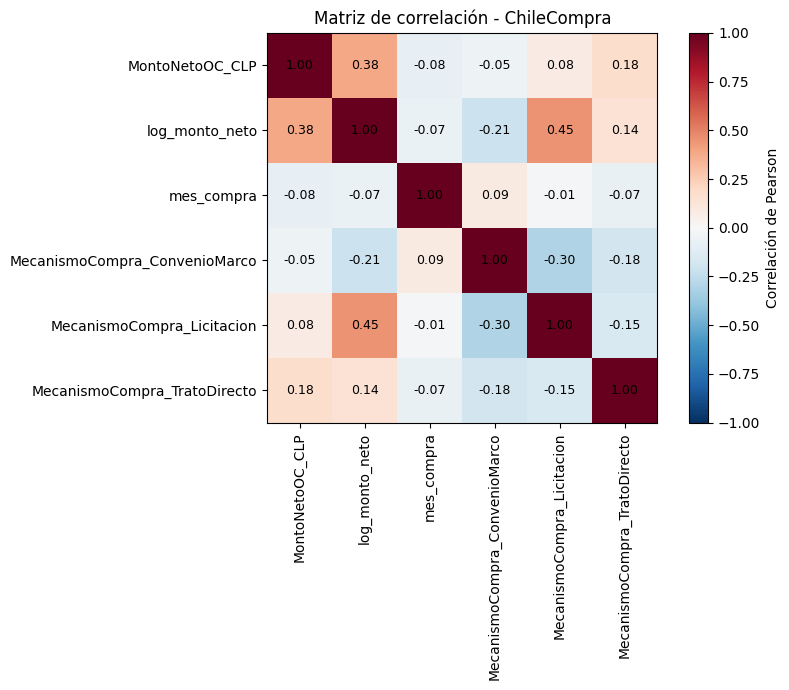

In [39]:

import matplotlib.pyplot as plt

# Seleccionar variables numéricas relevantes
variables = [
    "MontoNetoOC_CLP",
    "log_monto_neto",
    "mes_compra",
    "MecanismoCompra_ConvenioMarco",
    "MecanismoCompra_Licitacion",
    "MecanismoCompra_TratoDirecto"
]

# Calcular la matriz de correlación de Pearson
corr = df[variables].corr()

# Mostrar resultados numéricos
display(corr.round(2))

# Graficar la matriz
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)

ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

# Mostrar coeficientes dentro de cada celda
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(im, ax=ax, label="Correlación de Pearson")
plt.title("Matriz de correlación - ChileCompra")
plt.tight_layout()
plt.show()


**Actividad 2.2 — Matriz de correlación**

La matriz de correlación de Pearson permitió examinar las asociaciones entre los montos netos, su transformación logarítmica, el mes de compra y los indicadores binarios de los mecanismos de contratación.

Los dos pares con mayor correlación en valor absoluto, excluyendo la diagonal principal, fueron **log_monto_neto** y **MecanismoCompra_Licitacion** (r = 0,45), y **MontoNetoOC_CLP** y **log_monto_neto** (r = 0,38).

La primera relación evidencia una asociación positiva moderada entre las órdenes clasificadas como Licitación y los montos expresados en escala logarítmica. Este resultado es coherente con la mayor mediana monetaria observada para dicho mecanismo en el análisis por grupos.

La segunda relación corresponde a una variable monetaria y su transformación logarítmica, por lo que no constituye un hallazgo independiente.

Por otra parte, **mes_compra** presenta correlaciones cercanas a cero con las variables monetarias, lo que indica una asociación lineal muy débil a nivel de orden individual. También se observan correlaciones negativas entre indicadores de mecanismos, explicadas parcialmente por su carácter mutuamente excluyente.

**Conclusión:** Los resultados sugieren diferencias en los montos según el mecanismo de contratación, especialmente en Licitación. Sin embargo, las correlaciones identificadas son descriptivas y no demuestran causalidad. Será necesario considerar otras variables, como el Gobierno Regional y las características de las adquisiciones, para profundizar en su interpretación.

### ✏️ Actividad 2.3 — El par más correlacionado, bajo sospecha

Toma el par con mayor correlación y **no te quedes con el número**. Haz el recorrido del Ejercicio 4:

1. Grafica el diagrama de dispersión. ¿La relación es lineal, o el coeficiente engaña?
2. ¿Alguna de las dos variables depende del **tamaño** de la unidad de análisis? Si es así, **normalízalas** y vuelve a calcular.
3. Piensa qué **tercera variable** podría estar causando ambas, y calcula la correlación parcial.
4. Si tienes una variable de agrupación, repite el cálculo **dentro de un solo grupo**.

1) Graficar el diagrama de dispersión:

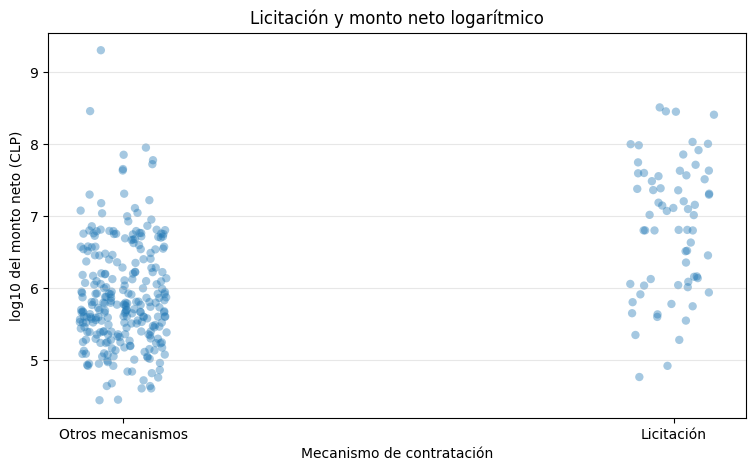

In [40]:

import matplotlib.pyplot as plt
import numpy as np

# Variables del par más correlacionado
x = df["MecanismoCompra_Licitacion"]
y = df["log_monto_neto"]

# Separar visualmente puntos superpuestos
np.random.seed(42)
x_visual = x + np.random.uniform(
    -0.08, 0.08, size=len(x)
)

# Diagrama de dispersión
plt.figure(figsize=(9, 5))

plt.scatter(
    x_visual,
    y,
    alpha=0.4,
    edgecolors="none"
)

plt.title("Licitación y monto neto logarítmico")
plt.xlabel("Mecanismo de contratación")
plt.ylabel("log10 del monto neto (CLP)")

plt.xticks(
    [0, 1],
    ["Otros mecanismos", "Licitación"]
)

plt.grid(axis="y", alpha=0.3)
plt.show()


**Paso 1 — Diagrama de dispersión**

El diagrama de dispersión presenta dos grupos correspondientes a las órdenes clasificadas como Licitación y aquellas pertenecientes a otros mecanismos de contratación.

Se observa que las licitaciones tienden a concentrarse en valores logarítmicos más elevados, mientras que los demás mecanismos presentan una mayor concentración en rangos inferiores. No obstante, existe superposición entre ambos grupos y se identifican valores extremos.

Debido a que **MecanismoCompra_Licitacion** es una variable binaria, no corresponde interpretar el gráfico como una relación lineal continua tradicional. El coeficiente de Pearson (r = 0,45) representa una asociación positiva moderada entre pertenecer al mecanismo Licitación y presentar montos netos más elevados en escala logarítmica, pero no demuestra causalidad.

Por lo tanto, la correlación resulta descriptivamente útil, siempre que se interprete como una comparación entre dos grupos y no como una relación causal entre variables continuas.

**Paso 2 — Evaluación de normalización por tamaño**

La unidad de análisis corresponde a una orden de compra individual. La variable **MecanismoCompra_Licitacion** es binaria y no depende del tamaño de la contratación. Por su parte, **log_monto_neto** representa el monto monetario transformado a escala logarítmica.

Aunque los montos pueden estar relacionados con la cantidad de bienes o servicios contratados, el conjunto preparado no dispone de una medida homogénea del tamaño de cada orden que permita normalizarlos de manera comparable.

Por esta razón, no se aplicó una normalización adicional por tamaño ni se recalculó la correlación mediante una razón artificial. Se mantiene el coeficiente original de Pearson (r = 0,45), reconociendo que las diferencias en el alcance de las contrataciones podrían influir en la asociación observada.

In [41]:

import pandas as pd
from sklearn.linear_model import LinearRegression

# Variables que queremos relacionar
x = df["MecanismoCompra_Licitacion"]
y = df["log_monto_neto"]

# Tercera variable: Gobierno Regional
regiones = pd.get_dummies(
    df["RegionOrigen"],
    drop_first=True,
    dtype=int
)

# Correlación original
r_original = x.corr(y)

# Modelos para controlar el efecto de la región
modelo_x = LinearRegression().fit(regiones, x)
modelo_y = LinearRegression().fit(regiones, y)

# Residuos después de considerar la región
residuo_x = x - modelo_x.predict(regiones)
residuo_y = y - modelo_y.predict(regiones)

# Correlación parcial
r_parcial = residuo_x.corr(residuo_y)

print(f"Correlación original: {r_original:.4f}")
print(f"Correlación parcial controlando región: {r_parcial:.4f}")
print(f"Diferencia: {r_parcial - r_original:+.4f}")


Correlación original: 0.4483
Correlación parcial controlando región: 0.4376
Diferencia: -0.0106


**Paso 3 — Evaluación de una posible variable confundidora**

Se seleccionó **RegionOrigen** como posible variable confundidora, considerando que los Gobiernos Regionales pueden presentar diferencias en los montos y mecanismos de contratación utilizados.

Para evaluar su influencia, se calculó una correlación parcial mediante regresión lineal y análisis de residuos, controlando las tres categorías regionales a través de variables indicadoras.

La correlación original entre **MecanismoCompra_Licitacion** y **log_monto_neto** fue de **r = 0,4483**, mientras que la correlación parcial controlando por Gobierno Regional fue de **r = 0,4376**, con una diferencia de aproximadamente −0,0106.

La pequeña variación indica que la asociación positiva moderada se mantiene prácticamente estable después del ajuste. Por tanto, las diferencias promedio entre regiones no parecen explicar una parte importante de la correlación observada.

No obstante, este resultado no demuestra causalidad ni descarta la influencia de otros factores, como el tipo de adquisición, la magnitud de los contratos o las características de los organismos compradores.

In [42]:

# Seleccionar un solo Gobierno Regional
df_metropolitana = df[
    df["RegionOrigen"] == "Metropolitana"
].copy()

# Comprobar el tamaño del grupo
print("Órdenes de la Región Metropolitana:",
      len(df_metropolitana))

print("Distribución por mecanismo:")
print(df_metropolitana["MecanismoCompra"].value_counts())

# Calcular correlación dentro del grupo
r_metropolitana = df_metropolitana[
    "MecanismoCompra_Licitacion"
].corr(
    df_metropolitana["log_monto_neto"]
)

print(f"Correlación general: {r_original:.4f}")
print(f"Correlación Metropolitana: {r_metropolitana:.4f}")


Órdenes de la Región Metropolitana: 131
Distribución por mecanismo:
MecanismoCompra
CompraAgil       65
Licitacion       35
ConvenioMarco    16
TratoDirecto     15
Name: count, dtype: int64
Correlación general: 0.4483
Correlación Metropolitana: 0.5471


**Paso 4 — Correlación dentro de un grupo**

Se seleccionó la Región Metropolitana para repetir el análisis, debido a que presenta la mayor cantidad de órdenes de compra del conjunto, con 131 registros. De estos, 35 corresponden a Licitación y 96 a otros mecanismos de contratación.

La correlación entre **MecanismoCompra_Licitacion** y **log_monto_neto** alcanzó **r = 0,5471**, superior a la correlación general de **r = 0,4483**.

Este resultado evidencia una asociación positiva moderada, algo más pronunciada dentro de la Región Metropolitana. En otras palabras, las órdenes clasificadas como Licitación tienden a presentar montos logarítmicos mayores que las de otros mecanismos dentro de este grupo.

No obstante, se trata de una asociación descriptiva y no causal. Además, los resultados corresponden a un subconjunto de 131 órdenes, por lo que no deben generalizarse automáticamente a las demás regiones.

**Conclusión de la Actividad 2.3**

El análisis permitió examinar críticamente la correlación entre el mecanismo Licitación y el monto neto logarítmico de las órdenes de compra.

El diagrama de dispersión evidenció diferencias entre los grupos, aunque también presentó superposición de valores. Debido al carácter binario de la variable de mecanismo, la asociación se interpretó como una comparación entre categorías y no como una relación lineal continua tradicional.

La correlación parcial controlando por Gobierno Regional disminuyó levemente respecto de la original, de 0,4483 a 0,4376, lo que sugiere que las diferencias promedio entre regiones no explican una parte importante de la asociación observada.

Al restringir el análisis a la Región Metropolitana, la correlación aumentó a 0,5471, evidenciando que la intensidad de la asociación puede variar entre subconjuntos de datos.

En conjunto, los resultados respaldan la existencia de una asociación descriptiva entre el mecanismo de Licitación y montos netos más elevados, sin demostrar causalidad. Factores adicionales, como el tipo de adquisición y la magnitud de los contratos, podrían influir en esta relación.

---
## Parte 3 · Series temporales

**Si tu conjunto tiene una variable de fecha, esta parte es obligatoria.** Si no la tiene, reemplázala por un análisis bivariado adicional y dilo explícitamente aquí.

### ✏️ Actividad 3.1 — Construir la serie

Agrega tu conjunto por período (mes, semana o día, según corresponda) y grafica la evolución de tu métrica principal.

Monto neto acumulado por mes:


,MontoNetoOC_CLP
mes_compra,
1,6.616806e+08
2,2.204277e+09
3,8.057480e+08
4,2.970634e+08
5,5.210437e+08
6,1.108146e+09


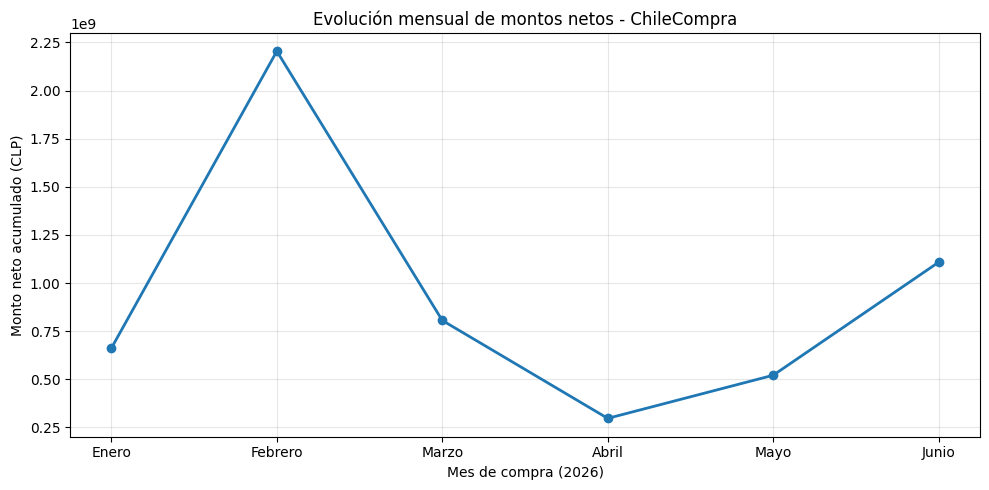

In [43]:
# Tu código aquí.

import matplotlib.pyplot as plt

# Agrupar los montos netos por mes
serie_mensual = (
    df.groupby("mes_compra")["MontoNetoOC_CLP"]
    .sum()
    .sort_index()
)

# Mostrar los resultados
print("Monto neto acumulado por mes:")
display(serie_mensual)

# Graficar la evolución mensual
plt.figure(figsize=(10, 5))

plt.plot(
    serie_mensual.index,
    serie_mensual.values,
    marker="o",
    linewidth=2
)

plt.title("Evolución mensual de montos netos - ChileCompra")
plt.xlabel("Mes de compra (2026)")
plt.ylabel("Monto neto acumulado (CLP)")

plt.xticks(
    [1, 2, 3, 4, 5, 6],
    ["Enero", "Febrero", "Marzo",
     "Abril", "Mayo", "Junio"]
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Actividad 3.1 — Evolución mensual de montos netos**

La serie temporal presenta fluctuaciones importantes en los montos netos acumulados de las órdenes de compra durante el primer semestre de 2026.

Febrero registra el mayor monto, con aproximadamente 2.204 millones CLP, mientras que abril presenta el menor, con cerca de 297 millones CLP Después del máximo de febrero, se observa una disminución durante marzo y abril, seguida de una recuperación en mayo y junio.

Al comparar estos resultados con la frecuencia mensual de órdenes, se evidencia que una mayor cantidad de contrataciones no implica necesariamente un mayor monto acumulado. Por ejemplo, junio presenta 81 órdenes, frente a las 46 de febrero, pero su monto total es considerablemente inferior.

Las variaciones podrían estar influenciadas por contrataciones de gran magnitud, considerando la presencia de valores atípicos identificados anteriormente.

**Conclusión:** La distribución temporal de los montos netos es irregular y no presenta una tendencia creciente sostenida. Para comprender estas fluctuaciones resulta necesario considerar tanto la cantidad de órdenes como su magnitud monetaria y la posible influencia de valores extremos.

In [44]:

# Revisar las cinco órdenes de mayor monto en febrero
febrero = df[df["mes_compra"] == 2]

display(
    febrero[
        [
            "codigoOC",
            "RegionOrigen",
            "MecanismoCompra",
            "MontoNetoOC_CLP"
        ]
    ]
    .sort_values("MontoNetoOC_CLP", ascending=False)
    .head(5)
)


,codigoOC,RegionOrigen,MecanismoCompra,MontoNetoOC_CLP
225,1003780-2-SE26,Metropolitana,TratoDirecto,2.016712e+09
85,624-10-SE26,Coquimbo,Licitacion,3.600000e+07
201,4289-2-SE26,Metropolitana,Licitacion,2.400000e+07
103,624-4-TD26,Coquimbo,TratoDirecto,2.057600e+07
329,836-7-TD26,Valparaiso,TratoDirecto,1.522224e+07


**Análisis complementario del máximo registrado en febrero**

Al examinar las órdenes de mayor monto correspondientes a febrero, se identificó que la orden `1003780-2-SE26`, emitida por el Gobierno Regional Metropolitano mediante Trato Directo, registra un monto neto de aproximadamente $2.016,71 millones CLP.

Esta contratación representa cerca del 91,5 % del monto neto acumulado de febrero, que alcanza aproximadamente $2.204,28 millones CLP.

Por lo tanto, el máximo observado en la serie temporal se encuentra fuertemente influido por una sola orden de gran magnitud, y no necesariamente refleja un aumento generalizado de los montos de contratación durante dicho mes.

Este hallazgo evidencia la importancia de considerar los valores atípicos al interpretar las fluctuaciones temporales y demuestra que los montos acumulados pueden diferir considerablemente de los patrones observados en la frecuencia de órdenes.

### ✏️ Actividad 3.2 — Descomposición

Si tu serie tiene al menos **dos ciclos completos** (por ejemplo, 24 meses), descompónla en tendencia, estacionalidad y residuo.

Después responde: ¿qué muestra el **residuo**? ¿Hay algún período anómalo?


**Justificación de no aplicación:**

No se realizó una descomposición de la serie temporal en tendencia, estacionalidad y residuos, debido a que el conjunto de datos comprende únicamente seis meses, desde enero hasta junio de 2026.

Según el criterio establecido en la actividad, este procedimiento requiere al menos dos ciclos completos. Para analizar una posible estacionalidad anual con frecuencia mensual serían necesarios, como mínimo, 24 meses de información.

Adicionalmente, el análisis de la Actividad 3.1 evidenció que el máximo registrado en febrero está fuertemente influido por una sola orden de compra, equivalente aproximadamente al 91,5 % del monto acumulado de ese mes.

Por lo tanto, las fluctuaciones observadas no constituyen evidencia suficiente de patrones estacionales recurrentes. Se optó por mantener un análisis descriptivo de la evolución mensual, reconociendo la limitada cobertura temporal y la influencia de valores extremos.

**Conclusión:** Con la información disponible es posible identificar variaciones entre meses, pero no establecer una tendencia de largo plazo ni confirmar la existencia de estacionalidad anual.

### ✏️ Actividad 3.3 — La comparación honesta

Si tu serie tiene estacionalidad, calcula la variación entre dos períodos consecutivos y la variación interanual del mismo período. Muestra la diferencia entre ambas lecturas (Ejercicio 6).

In [45]:
# Tu código aquí

# Variación entre meses consecutivos
variacion_mensual = serie_mensual.pct_change() * 100

# Mostrar los resultados
print("Variación porcentual mensual:")
display(variacion_mensual.round(2))


Variación porcentual mensual:


,MontoNetoOC_CLP
mes_compra,
1,NaN
2,233.13
3,-63.45
4,-63.13
5,75.40
6,112.68


**Actividad 3.3 — La comparación honesta**

Se calculó la variación porcentual de los montos netos acumulados entre meses consecutivos del primer semestre de 2026, utilizando `pct_change()`.

Los resultados evidencian fluctuaciones importantes: febrero presenta un aumento de 233,13 % respecto de enero, seguido de disminuciones de 63,45 % en marzo y 63,13 % en abril. Posteriormente, se observan incrementos de 75,40 % en mayo y 112,68 % en junio.

El aumento de febrero debe interpretarse con cautela, debido a que una sola orden de compra de aproximadamente $2.017 millones representa el 91,5 % del monto acumulado de ese mes. Esto demuestra que una variación mensual elevada no necesariamente refleja un aumento generalizado de los montos de contratación.

Debido a que el conjunto solamente contiene información de enero a junio de 2026, no es posible calcular variaciones interanuales ni comprobar patrones estacionales recurrentes.

**Conclusión:** La comparación entre períodos consecutivos permite describir cambios de corto plazo, pero no sustituye una comparación interanual. Para evaluar si estas fluctuaciones corresponden a patrones estacionales, sería necesario incorporar datos equivalentes de años anteriores.

---
## Parte 4 · Hipótesis de trabajo

Esto es lo que la semana 4 va a poner a prueba. Una hipótesis de trabajo no es una corazonada: es una afirmación **falsable** que surge de la evidencia que acabas de producir.

### ✏️ Actividad 4.1 — Formula dos hipótesis

Cada una debe indicar:

- **La afirmación**, en una frase.
- **La evidencia exploratoria** que la sugiere (qué gráfico, qué número, en qué celda).
- **Qué la refutaría**: qué tendrías que observar para descartarla.
- **Qué confundidor podría explicarla** sin que la relación sea real.

Si no puedes escribir qué la refutaría, no es una hipótesis: es una opinión.

# **Hipótesis 1 — Diferencias monetarias según el mecanismo de contratación**

**Afirmación:** Las órdenes de compra realizadas mediante Licitación presentan una mediana de monto neto superior a las órdenes gestionadas mediante Compra Ágil en los tres Gobiernos Regionales analizados.

**Evidencia exploratoria:** En la Actividad 2.1, el análisis mediante `groupby()` mostró que las 68 órdenes de Licitación presentan una mediana de 10.426.694,50 CLP, mientras que las 151 órdenes de Compra Ágil registran una mediana de 644.670 CLP. Además, la matriz de correlación de la Actividad 2.2 identificó una asociación positiva moderada entre Licitación y el monto logarítmico (r = 0,4483), que se mantuvo al controlar por Gobierno Regional (r parcial = 0,4376) en la Actividad 2.3.

**¿Qué la refutaría?** Al evaluar una muestra independiente o nuevos períodos, observar que la mediana de Licitación es igual o inferior a la de Compra Ágil, o que la diferencia no se sostiene bajo el criterio estadístico definido para la prueba.

**Posible variable confundidora:** El tipo y la magnitud de los bienes o servicios contratados. Las licitaciones podrían corresponder con mayor frecuencia a proyectos de infraestructura o adquisiciones de gran escala, mientras que Compra Ágil podría concentrar contrataciones menores. Estas diferencias podrían explicar la asociación monetaria observada sin que el mecanismo de contratación sea su causa directa.

# **Hipótesis 2 — Influencia de los valores extremos en los montos mensuales**

**Afirmación:** Los montos netos acumulados mensualmente presentan una elevada sensibilidad a las órdenes de compra de mayor importe, de manera que su exclusión produce cambios importantes en la distribución mensual de los montos.

**Evidencia exploratoria:** En la Actividad 3.1, febrero registró el mayor monto acumulado, aproximadamente 2.204,28 millones CLP, a pesar de contar con solo 46 órdenes. Una única contratación de Trato Directo, por aproximadamente 2.016,71 millones, representó el 91,5 % del monto de ese mes.

**¿Qué la refutaría?** Que, al excluir la orden de mayor monto de cada mes, los montos acumulados, las posiciones relativas de los meses y la concentración monetaria cambiaran muy poco, según un criterio de sensibilidad definido previamente.

**Posible factor explicativo:** La composición de los mecanismos de contratación y la magnitud de las adquisiciones realizadas por cada Gobierno Regional podrían explicar por qué determinados períodos concentran órdenes de importes excepcionalmente elevados.

---
## Parte 5 · Cierre y versionado

In [46]:
# Guarda el conjunto con las variables derivadas que hayas creado esta semana
df.to_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', index=False)
print('Guardado:', df.shape)

Guardado: (336, 14)


In [47]:
# En una terminal:
# git add S3_Notebook_Laboratorio_CDD.ipynb mi_conjunto_explorado.csv
# git commit -m 'Semana 3: analisis exploratorio y series temporales'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de entregar

- [ ] Al menos tres distribuciones graficadas y **leídas**, no solo mostradas
- [ ] Media contra mediana decidida y justificada
- [ ] Comparación por grupos con el `count` incluido
- [ ] Matriz de correlación calculada e interpretada
- [ ] El par más correlacionado sometido al recorrido de confundidores
- [ ] Serie temporal descompuesta, con lectura del residuo (o justificación de por qué no aplica)
- [ ] Dos hipótesis de trabajo, cada una con qué la refutaría
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

Recuerda: **esta semana no hay sesión sincrónica**. Las dudas, al Foro de Consultas.

_Ciencia de Datos · Advance UCSC · Semana 3_